# # 05 · Attention variants: MHA, MQA, GQA, sliding window, MLA
#
# The attention layer is where most inference cost lives (the **KV cache**). Different designs trade quality for memory/compute:
#
# | variant | idea | used by |
# |---|---|---|
# | **MHA** | every head has its own K,V | GPT-2/3, BERT |
# | **MQA** | one K,V shared by all heads | PaLM, Falcon |
# | **GQA** | K,V shared per *group* of heads | LLaMA-2/3, Mistral, Qwen |
# | **Sliding window** | each token sees only the last W tokens | Mistral-7B, Longformer |
# | **MLA** | compress K,V into a small *latent* vector | DeepSeek-V2/V3 |

---

### At a glance

| | |
|---|---|
| **Family** | Attention variants |
| **Representative models** | MHA, MQA (PaLM), GQA (LLaMA-3), sliding window (Mistral), MLA (DeepSeek-V2/V3) |
| **Core idea** | Share or compress keys/values, or restrict the visible window, to cut inference cost. |
| **Compute / memory** | KV cache from 2·H·d_h per token (MHA) down to a small latent (MLA) |
| **Dataset** | tiny-Shakespeare (char level) – see notebook 00 |
| **Runtime** | ≈ 251 s on a laptop CPU |

### What you will learn

- Visualise attention masks and head layouts
- Quantify KV-cache size for a 70B-class model
- Train all variants under one budget

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import math
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np, pandas as pd
from llmarch import *
setup_style()
from llmarch.blocks import *
set_seed(0); device = get_device(); STEPS = 1000
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]

# ## Who can see whom? (masks)

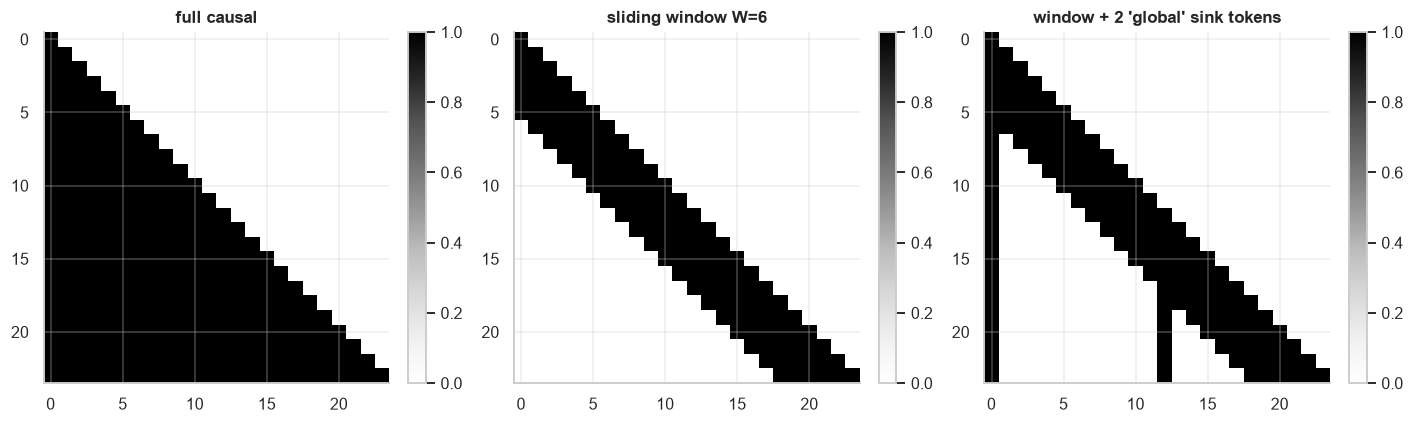

In [2]:
T = 24
def mask(window=None):
    a = Attention(8, 2, window=window); return a.mask(T, "cpu").float()
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
plot_heatmap(mask(), title="full causal", ax=axs[0], cmap="Greys"); plot_heatmap(mask(6), title="sliding window W=6", ax=axs[1], cmap="Greys")
# dilated/global (BigBird-ish) example
g = mask(6).clone(); g[:, 0] = 1; g[:, 12] = (torch.arange(T) >= 12).float()
plot_heatmap(g, title="window + 2 'global' sink tokens", ax=axs[2], cmap="Greys"); plt.tight_layout(); plt.show()

# ## Head layouts
# MHA/MQA/GQA are the same code with a different number of KV heads (`n_kv_head`). The rest is just `repeat_interleave`.

In [3]:
show_source(Attention)

```python
class Attention(nn.Module):
    """n_kv_head == n_head -> MHA, == 1 -> MQA, in between -> GQA. window -> sliding-window causal attention.
    Set `keep_attn=True` to store the last attention probabilities in `self.last_attn` (B, H, T, T)."""
    def __init__(self, d, n_head, n_kv_head=None, rope=False, window=None, causal=True, bias=True):
        super().__init__()
        self.h, self.hkv = n_head, n_kv_head or n_head
        assert d % n_head == 0 and n_head % self.hkv == 0
        self.hd = d // n_head; self.rope, self.window, self.causal = rope, window, causal
        self.q = nn.Linear(d, n_head * self.hd, bias=bias)
        self.k = nn.Linear(d, self.hkv * self.hd, bias=bias)
        self.v = nn.Linear(d, self.hkv * self.hd, bias=bias)
        self.o = nn.Linear(d, d, bias=bias)
        self.keep_attn = False; self.last_attn = None

    def mask(self, T, device):
        i = torch.arange(T, device=device)[:, None]; j = torch.arange(T, device=device)[None, :]
        m = (j <= i) if self.causal else torch.ones(T, T, dtype=torch.bool, device=device)
        if self.window is not None:
            m = m & (i - j < self.window) if self.causal else m & ((i - j).abs() < self.window)
        return m

    def forward(self, x, pad_mask=None):
        B, T, _ = x.shape
        q = self.q(x).view(B, T, self.h, self.hd).transpose(1, 2)
        k = self.k(x).view(B, T, self.hkv, self.hd).transpose(1, 2)
        v = self.v(x).view(B, T, self.hkv, self.hd).transpose(1, 2)
        if self.rope:
            cos, sin = rope_cos_sin(T, self.hd, device=x.device)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if self.hkv != self.h:                                            # share KV heads across query groups
            k = k.repeat_interleave(self.h // self.hkv, 1); v = v.repeat_interleave(self.h // self.hkv, 1)
        m = self.mask(T, x.device)[None, None]
        if pad_mask is not None:                                          # (B, T) True = real token
            m = m & pad_mask[:, None, None, :]
        if self.keep_attn:
            s = (q @ k.transpose(-1, -2)) / math.sqrt(self.hd)
            p = s.masked_fill(~m, float("-inf")).softmax(-1)
            self.last_attn = p.detach(); y = p @ v
        else:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=m)
        return self.o(y.transpose(1, 2).reshape(B, T, -1))

```

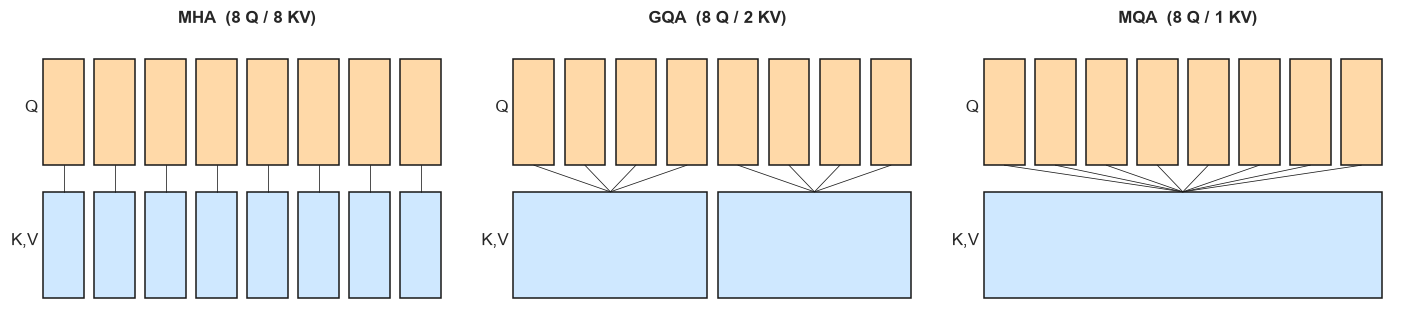

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, (name, kv) in zip(ax, [("MHA  (8 Q / 8 KV)", 8), ("GQA  (8 Q / 2 KV)", 2), ("MQA  (8 Q / 1 KV)", 1)]):
    for q in range(8): a.add_patch(plt.Rectangle((q, 1), .8, .8, fc="#ffd9a8", ec="k"))
    for k in range(kv):
        w = 8 / kv; a.add_patch(plt.Rectangle((k * w, 0), w - .2, .8, fc="#cfe8ff", ec="k"))
        for q in range(int(k * w), int((k + 1) * w)): a.plot([q + .4, k * w + (w - .2) / 2], [1, .8], "k-", lw=.5)
    a.set_xlim(-.2, 8.2); a.set_ylim(-.2, 2); a.axis("off"); a.set_title(name); a.text(-.1, 1.4, "Q", ha="right"); a.text(-.1, .4, "K,V", ha="right")
plt.tight_layout(); plt.show()

# ## MLA — Multi-head Latent Attention (DeepSeek)
# Instead of caching K and V (2·d numbers per token) cache one small **latent** `c = W_down x` (r numbers) and
# expand it with up-projections when needed. (The decoupled-RoPE detail of the real MLA is left out for clarity.)

In [5]:
class MLA(nn.Module):
    def __init__(self, d, n_head, r):
        super().__init__(); self.h, self.hd = n_head, d // n_head
        self.q = nn.Linear(d, d); self.kv_down = nn.Linear(d, r, bias=False)
        self.k_up = nn.Linear(r, d, bias=False); self.v_up = nn.Linear(r, d, bias=False); self.o = nn.Linear(d, d)
    def forward(self, x):
        B, T, D = x.shape; c = self.kv_down(x)                     # <- THIS is all that would be cached: (B,T,r)
        sp = lambda t: t.view(B, T, self.h, self.hd).transpose(1, 2)
        y = F.scaled_dot_product_attention(sp(self.q(x)), sp(self.k_up(c)), sp(self.v_up(c)), is_causal=True)
        return self.o(y.transpose(1, 2).reshape(B, T, D))

# ## KV-cache memory per token (the reason these variants exist)
# For a LLaMA-70B-like config: 80 layers, d=8192, 64 heads, head-dim 128, fp16.

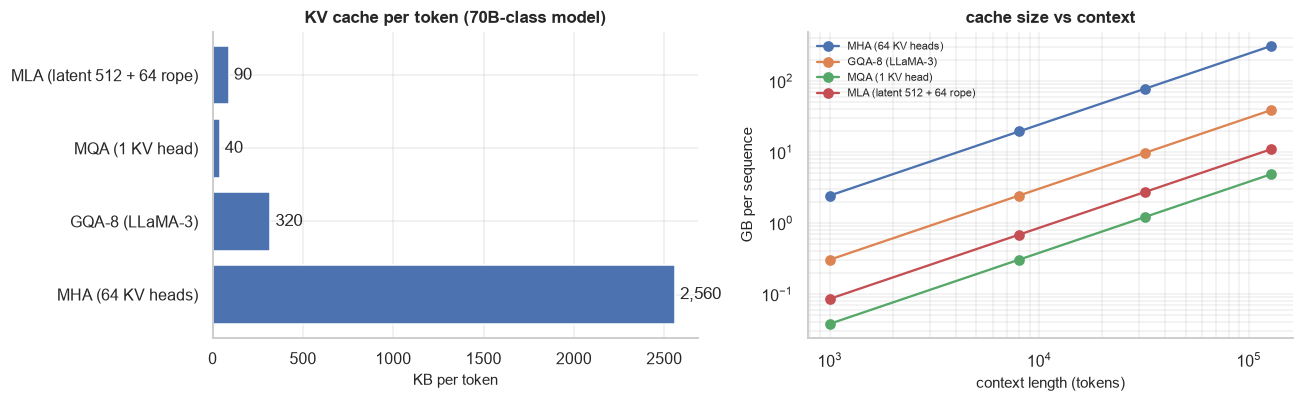

In [6]:
L, dm, nh, hd, bytes_ = 80, 8192, 64, 128, 2
cfgs = {"MHA (64 KV heads)": 2 * 64 * hd, "GQA-8 (LLaMA-3)": 2 * 8 * hd, "MQA (1 KV head)": 2 * 1 * hd, "MLA (latent 512 + 64 rope)": 512 + 64}
kb = {k: v * L * bytes_ / 1024 for k, v in cfgs.items()}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(list(kb), list(kb.values())); ax[0].set(xlabel="KB per token", title="KV cache per token (70B-class model)")
for i, v in enumerate(kb.values()): ax[0].text(v, i, f" {v:,.0f}", va="center")
ctx = np.array([1e3, 8e3, 32e3, 128e3])
for k, v in kb.items(): ax[1].loglog(ctx, v * ctx / 1024 / 1024, "o-", label=k)
ax[1].set(xlabel="context length (tokens)", ylabel="GB per sequence", title="cache size vs context"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()

# ## Train a small LM with each variant
# Same shell (`DecoderLM`, RoPE, RMSNorm, SwiGLU) — only the attention changes.

In [7]:
d, H = 96, 8
def mk(mixer):
    return DecoderLM(V, d, [Block(d, mixer(), SwiGLU(d)) for _ in range(3)])
variants = {
    "MHA": lambda: Attention(d, H, rope=True, bias=False),
    "GQA (2 kv)": lambda: Attention(d, H, 2, rope=True, bias=False),
    "MQA (1 kv)": lambda: Attention(d, H, 1, rope=True, bias=False),
    "Sliding window (W=16)": lambda: Attention(d, H, rope=True, window=16, bias=False),
    "MLA (latent 24)": lambda: MLA(d, H, 24),
}
rows, hists = [], {}
for name, mixer in variants.items():
    set_seed(0); m = mk(mixer); print("==", name, f"{count_params(m):,} params")
    hists[name] = train_lm(m, train, val, steps=STEPS, block_size=64, batch_size=32, lr=3e-3, device=device, eval_every=250, verbose=False)
    rows.append((name, count_params(m), hists[name]["val"][-1]))
df = pd.DataFrame(rows, columns=["variant", "params", "val_loss"]).set_index("variant"); df

== MHA 338,688 params


== GQA (2 kv) 297,216 params


== MQA (1 kv) 290,304 params


== Sliding window (W=16) 338,688 params


== MLA (latent 24) 304,704 params


,params,val_loss
variant,,
MHA,338688,1.687
GQA (2 kv),297216,1.69
MQA (1 kv),290304,1.678
Sliding window (W=16),338688,1.67
MLA (latent 24),304704,2.104


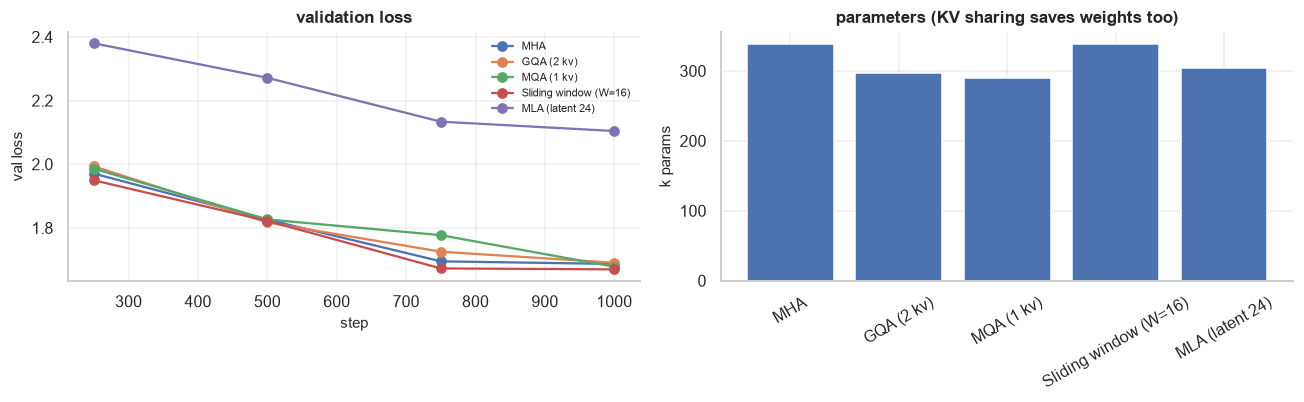

At this tiny scale the differences are small; the savings matter at long context / big batch (see KV chart above).


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for n, h in hists.items(): ax[0].plot(h["val_step"], h["val"], "o-", label=n)
ax[0].set(xlabel="step", ylabel="val loss", title="validation loss"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
ax[1].bar(df.index, df.params / 1e3); ax[1].set(ylabel="k params", title="parameters (KV sharing saves weights too)"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
print("At this tiny scale the differences are small; the savings matter at long context / big batch (see KV chart above).")

# ## Sliding window: information still travels through depth
# With window W and L layers a token can be influenced by tokens up to ~ **L·W** positions back.

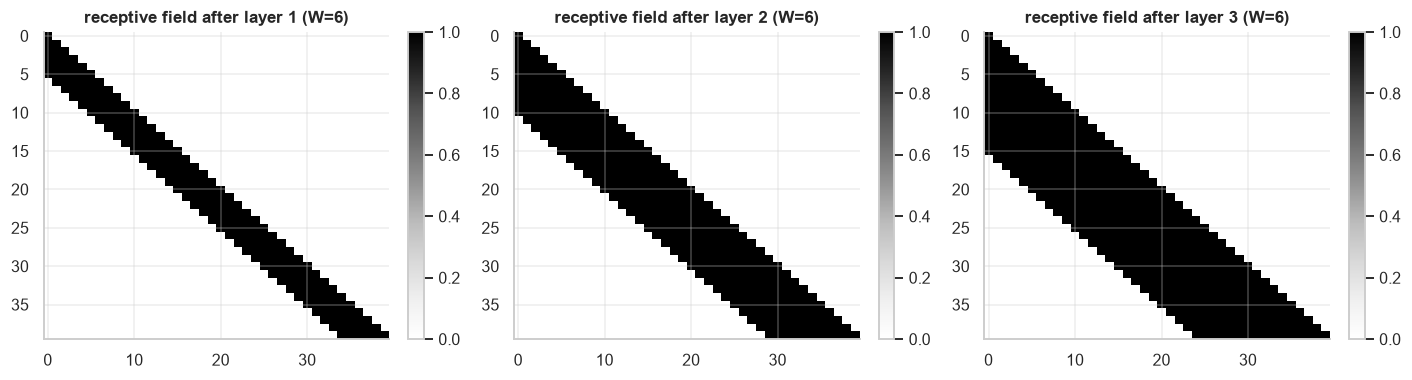

In [9]:
Tn, W, Ln = 40, 6, 3
i = torch.arange(Tn)[:, None]; j = torch.arange(Tn)[None, :]; A = ((j <= i) & (i - j < W)).float()
fig, axs = plt.subplots(1, Ln, figsize=(13, 3.6)); r = torch.eye(Tn)
for l in range(Ln):
    r = ((A @ r) > 0).float(); plot_heatmap(r, title=f"receptive field after layer {l+1} (W={W})", ax=axs[l], cmap="Greys")
plt.tight_layout(); plt.show()

---

## Key takeaways

- Decoding is memory-bandwidth bound, so shrinking the KV cache is the main lever for serving cost.
- MQA/GQA share K,V across query heads; MLA stores a low-rank latent instead.
- Sliding-window attention bounds cost per token, while depth still grows the receptive field to ≈ layers × window.

## References

- [Shazeer, *Fast Transformer Decoding: One Write-Head is All You Need* (MQA, 2019)](https://arxiv.org/abs/1911.02150)
- [Ainslie et al., *GQA* (2023)](https://arxiv.org/abs/2305.13245)
- [Beltagy et al., *Longformer* (2020)](https://arxiv.org/abs/2004.05150)
- [Jiang et al., *Mistral 7B* (2023)](https://arxiv.org/abs/2310.06825)
- [DeepSeek-AI, *DeepSeek-V2* (MLA, 2024)](https://arxiv.org/abs/2405.04434)

---
*← previous: `04_llama_style_modern_decoder`  ·  next: `06_positional_encodings` →*